# Early Warning of Food-Price Spikes in Tanzanian Markets
**Z3003 Data Mining: Scaling to Large Data — Mini-Project** · Shambhavi Srivastava (ZDA24B005) · BS Semester 5 (DSAI), IIT Madras Zanzibar

| | |
|---|---|
| **Decision question** | One month ahead, which market–commodity price series will see a **price spike** (a rise of more than 10% on the previous month), so that the **Ministry of Agriculture** can act early — releasing reserve stock or prioritising market monitoring? |
| **Mining task** | Classification (Weeks 6–7): predict `price_spike` (Yes/No) for month *t+1* using only information available at the end of month *t*. |
| **Dataset** | WFP *United Republic of Tanzania — Food Prices* and companion *Markets* table, via the Humanitarian Data Exchange (HDX). Licence CC BY-IGO. |
| **Approval** | Approved by Dr. I. Nyalala on 20 Oct 2026, with three conditions: **(1)** build every feature only from months before the month being predicted; **(2)** justify the 10% spike threshold; **(3)** convert prices to a common unit before modelling. Where each condition is met is flagged with **[Condition 1/2/3]**. |

**Data citation.** World Food Programme (2026). *United Republic of Tanzania — Food Prices* [`wfp_food_prices_tza.csv`, submitted as `Shambhavi_MiniProject_Data.csv`] and *Markets* [`wfp_markets_tza.csv`, submitted as `Shambhavi_MiniProject_Markets.csv`]. Humanitarian Data Exchange. https://data.humdata.org/dataset/wfp-food-prices-for-united-republic-of-tanzania. Licensed under CC BY-IGO. Downloaded 9 November 2026 (latest month in the file: September 2026).

**Note on the data version.** WFP updates this file monthly. The approval email (20 Oct) described an earlier version (65,107 rows, to Aug 2026); the version analysed here has 67,999 rows to Sep 2026. The structure is unchanged.

**Structure.** 1 Data understanding · 2 Exploratory analysis · 3 Preprocessing · 4 Mining · 5 Findings & discussion · References · Tools used.

In [13]:
# ---- Setup -------------------------------------------------------------------
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

def find_file(*names):
    # Look for each accepted name in data/, the notebook's own folder, then any Kaggle input folder.
    for name in names:
        candidates = [Path("data") / name, Path(name)] + sorted(Path("/kaggle/input").glob(f"**/{name}"))
        for p in candidates:
            if p.exists():
                return p
    raise FileNotFoundError(f"None of {names} found. Put the file in a 'data/' folder next to this notebook.")

# Submission names first (brief §2); the original WFP download names are accepted as a fallback.
PRICES_PATH  = find_file("Shambhavi_MiniProject_Data.csv", "wfp_food_prices_tza.csv")     # main price table
MARKETS_PATH = find_file("Shambhavi_MiniProject_Markets.csv", "wfp_markets_tza.csv")      # companion markets table
print("Using:", PRICES_PATH, "|", MARKETS_PATH)
RANDOM_STATE = 42                                      # one seed for every random step

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Plot style: recessive grid, thin marks, one fixed colour per entity
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 9.5,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})
COLOR = {"Retail": "#2a78d6", "Wholesale": "#eb6834"}   # fixed: Retail = blue, Wholesale = orange

# Library versions, for reproducibility and for the References section
import sys, matplotlib, scipy
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {matplotlib.__version__} | scipy {scipy.__version__}")

Using: wfp_food_prices_tza.csv | wfp_markets_tza.csv
Python 3.12.6 | pandas 3.0.2 | numpy 2.4.1 | matplotlib 3.10.8 | scipy 1.17.1


---
# 1 · Data Understanding

## 1.1 Shape of the data and what one row represents

In [14]:
df = pd.read_csv(PRICES_PATH, parse_dates=["date"])
markets = pd.read_csv(MARKETS_PATH)

print(f"Price table  : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Markets table: {markets.shape[0]:,} rows × {markets.shape[1]} columns")
print(f"Date range   : {df['date'].min():%b %Y} – {df['date'].max():%b %Y}")
df.head()

Price table  : 65,107 rows × 16 columns
Markets table: 123 rows × 7 columns
Date range   : Jan 2006 – Aug 2026


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2006-01-15,Arusha,Arusha Urban,Arusha (urban),80,-3.37,36.68,cereals and tubers,Maize,51,100 KG,actual,Wholesale,TZS,38464.29,32.46
1,2006-01-15,Arusha,Arusha Urban,Arusha (urban),80,-3.37,36.68,pulses and nuts,Beans,50,100 KG,actual,Wholesale,TZS,80714.29,68.11
2,2006-01-15,Dar-es-salaam,Ilala,Dar Es Salaam,83,-6.80,39.28,cereals and tubers,Maize,51,100 KG,actual,Wholesale,TZS,38742.86,32.69
3,2006-01-15,Dar-es-salaam,Ilala,Dar Es Salaam,83,-6.80,39.28,cereals and tubers,Rice,52,100 KG,actual,Wholesale,TZS,64545.45,54.47
4,2006-01-15,Dar-es-salaam,Ilala,Dar Es Salaam,83,-6.80,39.28,pulses and nuts,Beans,50,100 KG,actual,Wholesale,TZS,80000.00,67.51


In [15]:
# What is ONE row? Test the candidate key: market × commodity × unit × price type × month.
SERIES_KEY = ["market_id", "commodity", "unit", "pricetype"]

n_dup_rows = df.duplicated().sum()
n_dup_key  = df.duplicated(SERIES_KEY + ["date"]).sum()
n_series   = df.groupby(SERIES_KEY).ngroups
day_of_month = df["date"].dt.day.unique()

print(f"Fully duplicated rows                        : {n_dup_rows}")
print(f"Duplicates on (series key + month)           : {n_dup_key}")
print(f"Distinct price series (market×commodity×unit×type): {n_series}")
print(f"Day-of-month values in 'date'                : {day_of_month}")

Fully duplicated rows                        : 0
Duplicates on (series key + month)           : 0
Distinct price series (market×commodity×unit×type): 869
Day-of-month values in 'date'                : [15]


**What one row represents.** One row is **the monthly price of one commodity, in one market, in one unit, at one price level (retail or wholesale)** — e.g. *“wholesale maize in Arusha, per 100 kg, January 2006: 38,464 TZS.”*

- The combination *market × commodity × unit × price type × month* has **no duplicates**, so it is a valid key. This matters later: the spike label compares a row with the *same series* one month earlier, which is only well defined if each series has at most one price per month.
- The 67,999 rows belong to **870 separate price series**. The unit of analysis for the question is a *series-month*, not a market or a commodity on its own.
- Every date falls on the **15th**: WFP stamps each monthly price with the middle of the month. `date` therefore means “month”, not a specific day.

## 1.2 Attribute types

`df.dtypes` shows how pandas *stores* each column, which is not the same as its data-mining type (Tutorial 1 handout, §5). The profile below supplies the evidence for each classification.

In [16]:
profile = pd.DataFrame({
    "pandas dtype": df.dtypes.astype(str),
    "n unique":     df.nunique(),
    "example values": [", ".join(map(str, df[c].drop_duplicates().head(3).tolist())) for c in df.columns],
})
profile

,pandas dtype,n unique,example values
date,datetime64[us],247,"2006-01-15 00:00:00, 2006-02-15 00:00:00, 2006..."
admin1,str,25,"Arusha, Dar-es-salaam, Dodoma"
admin2,str,52,"Arusha Urban, Ilala, Mpwapwa"
market,str,63,"Arusha (urban), Dar Es Salaam, Dodoma (Majengo)"
market_id,int64,63,"80, 83, 84"
latitude,float64,59,"-3.37, -6.8, -7.29"
longitude,float64,59,"36.68, 39.28, 36.34"
category,str,7,"cereals and tubers, pulses and nuts, meat, fis..."
commodity,str,31,"Maize, Beans, Rice"
commodity_id,int64,31,"51, 50, 52"


Classification follows Lecture 2: **nominal** (=, ≠ only), **binary** (two states; symmetric or asymmetric), **ordinal** (adds <, >), **numeric** — **interval** (equal gaps, no true zero) or **ratio** (true zero, ratios meaningful); plus *discrete* vs *continuous*.

| # | Attribute | Type | Discrete / continuous | Valid centre | Reason |
|---|---|---|---|---|---|
| 1 | `date` | Numeric — **interval** | discrete (monthly) | median, mean | Differences are meaningful (Mar − Jan = 2 months) but there is no true zero, so “2026 is 1.0005× 2025” means nothing; same case as “calendar year” in Lecture 2. |
| 2 | `admin1` (region) | **Nominal** | discrete | mode | 25 region names with no order; we can only test equal / not equal. |
| 3 | `admin2` (district) | **Nominal** | discrete | mode | 52 district names nested inside regions; labels only. |
| 4 | `market` | **Nominal** | discrete | mode | 63 market names; labels only. |
| 5 | `market_id` | **Nominal** (identifier) | discrete | none | Stored as an integer, but it is a code: the mean of market IDs is meaningless (shown below). Same trap as `farm_id` in Tutorial 1. |
| 6 | `latitude` | Numeric — **interval** | continuous | median, mean | Equal gaps in degrees, but 0° (the equator) is a convention, not “no latitude”, and values can be negative, so ratios are meaningless. |
| 7 | `longitude` | Numeric — **interval** | continuous | median, mean | Same reasoning as latitude (0° = Greenwich, a convention). |
| 8 | `category` | **Nominal** | discrete | mode | 7 food groups (cereals, pulses, …) with no order. |
| 9 | `commodity` | **Nominal** | discrete | mode | 31 food items; labels only. |
| 10 | `commodity_id` | **Nominal** (identifier) | discrete | none | Integer code for `commodity`; arithmetic on it is meaningless. |
| 11 | `unit` | **Nominal** | discrete | mode | KG, 100 KG, MT, L. One could order the weight units by size, but L (litre) measures volume and cannot be placed on the same scale, so there is no single order: nominal. |
| 12 | `priceflag` | **Nominal** (constant) | discrete | mode | Only one value (`actual`) in this file, so it carries no information. |
| 13 | `pricetype` | **Binary — symmetric** | discrete | mode / proportion | Two states, Retail / Wholesale, and neither is the “rare, important” state: both price levels matter equally to the question. |
| 14 | `currency` | **Nominal** (constant) | discrete | mode | Only one value (`TZS`); carries no information. |
| 15 | `price` | Numeric — **ratio** | continuous | median, mean | 0 TZS means “free”, so 20,000 TZS is twice 10,000 TZS. **But** it is recorded in mixed units, so two rows are only comparable after conversion to TZS/kg **[Condition 3]**. |
| 16 | `usdprice` | Numeric — **ratio** | continuous | median, mean | Same as `price`, converted to US dollars by WFP; a derived, redundant column (see quality checks in 1.3). |
| — | `price_tzs_per_kg` *(derived, Section 3)* | Numeric — **ratio** | continuous | median, mean | `price` divided by kilograms per unit; the common unit required by Condition 3. |
| — | `price_spike` *(derived target)* | **Binary — asymmetric** | discrete | proportion | Yes / No. The two states are **not** equally important: a spike is the rare, costly event the Ministry wants to catch, so it is coded 1 and evaluated with recall/precision rather than accuracy (Lecture 1: “99.5% accuracy can catch zero fraud”). |

**No ordinal attribute exists in the raw data.** The brief requires numeric plus *at least one* of nominal / binary / ordinal, which is met. An ordinal attribute can be derived later by discretizing price change into ordered bands (Section 3).

In [17]:
# The identifier trap (Lecture 2): pandas will happily average an ID.
print(f"Mean of market_id    = {df['market_id'].mean():,.1f}   <- no market has this meaning")
print(f"Mean of commodity_id = {df['commodity_id'].mean():,.1f}   <- 'average commodity' does not exist")

# Constant columns: one value only, so zero information
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns:", {c: df[c].iloc[0] for c in constant_cols})

# Balance of the binary attribute and size of each nominal attribute
print("\npricetype:", df["pricetype"].value_counts().to_dict())
print("unit     :", df["unit"].value_counts().to_dict())

Mean of market_id    = 3,429.2   <- no market has this meaning
Mean of commodity_id = 241.4   <- 'average commodity' does not exist
Constant columns: {'priceflag': 'actual', 'currency': 'TZS'}

pricetype: {'Retail': 43954, 'Wholesale': 21153}
unit     : {'KG': 40996, '100 KG': 21126, 'L': 2958, 'MT': 27}


## 1.3 Missing values and data quality

Missingness in a time-series table can take two forms, and both must be counted:

1. **Explicit**: an empty cell in a row that exists.
2. **Implicit**: a month with **no row at all** for a series that is otherwise being monitored. These do not show up in `isna()`, but they are what breaks a month-on-month spike label.

### 1.3.1 Explicit missing values, per column

In [18]:
explicit = pd.DataFrame({"missing cells": df.isna().sum(),
                         "% of rows": (df.isna().mean() * 100).round(2)})
explicit.T

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
missing cells,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
% of rows,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Every column is complete: 0 empty cells out of 67,999 × 16.** WFP publishes only months for which a price was collected, so a missing price is represented by a **missing row**, not a blank cell. The real missing-data question is therefore the implicit one below.

### 1.3.2 Implicit missing values: months with no row

For each of the 870 series, we build the complete list of months between its **first and last observation**, and mark each month as observed or missing. Months *before* a series starts or *after* it stops are not counted as missing: those reflect when WFP monitored that series, which is analysed separately.

In [19]:
# Work with monthly periods so that month arithmetic is exact
df["month"] = df["date"].dt.to_period("M")

spans = (df.groupby(SERIES_KEY)
           .agg(first=("month", "min"), last=("month", "max"), observed=("month", "size"),
                admin1=("admin1", "first"), category=("category", "first"))
           .reset_index())

# Full monthly grid inside each series' active span
grid = spans.loc[spans.index.repeat((spans["last"] - spans["first"]).apply(lambda x: x.n) + 1)].copy()
grid["month"] = grid["first"] + grid.groupby(level=0).cumcount()
grid = grid.reset_index(drop=True)

observed_keys = df[SERIES_KEY + ["month"]].assign(present=True)
grid = grid.merge(observed_keys, on=SERIES_KEY + ["month"], how="left")
grid["missing"] = grid["present"].isna()
grid = grid.drop(columns="present")

n_expected, n_missing = len(grid), int(grid["missing"].sum())
assert n_expected - n_missing == len(df), "every observed row must sit inside the grid"

print(f"Expected series-months (inside active spans): {n_expected:,}")
print(f"Observed                                    : {n_expected - n_missing:,}")
print(f"Missing (no row)                            : {n_missing:,}  ({n_missing / n_expected:.1%})")

per_series = grid.groupby(SERIES_KEY)["missing"].sum()
print(f"\nSeries with no gaps: {(per_series == 0).sum()} of {len(per_series)};"
      f"  worst series missing {per_series.max()} months")

Expected series-months (inside active spans): 72,748
Observed                                    : 65,107
Missing (no row)                            : 7,641  (10.5%)

Series with no gaps: 419 of 869;  worst series missing 125 months


### 1.3.3 Are the gaps random or systematic?

If gaps were **missing completely at random**, the missing rate would be about the same for every price type, region, year and calendar month. We compare the rates and test independence with a χ² test (missing yes/no × group).

In [20]:
def missing_rate(by):
    t = grid.groupby(by)["missing"].agg(missing="sum", expected="size")
    t["rate %"] = (100 * t["missing"] / t["expected"]).round(1)
    return t

def chi2_test(col):
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(grid[col], grid["missing"]))
    return f"χ² = {chi2:,.0f}, dof = {dof}, p = {p:.1e}"

print("By price type:"); display(missing_rate("pricetype"))
print("Independence test, pricetype × missing:", chi2_test("pricetype"))

by_region = missing_rate("admin1").sort_values("rate %")
print("\nBy region — 5 most and 5 least complete:")
display(pd.concat([by_region.head(5), by_region.tail(5)]))
print("Independence test, region × missing:", chi2_test("admin1"))

grid["cal_month"] = grid["month"].dt.month
print("\nBy calendar month (seasonality check), rate %:")
print(missing_rate("cal_month")["rate %"].to_dict())

By price type:


,missing,expected,rate %
pricetype,,,
Retail,2595,46549,5.6
Wholesale,5046,26199,19.3


Independence test, pricetype × missing: χ² = 3,339, dof = 1, p = 0.0e+00

By region — 5 most and 5 least complete:


,missing,expected,rate %
admin1,,,
Simiyu,87,2024,4.3
Dodoma,175,3110,5.6
Morogoro,172,3031,5.7
Tanga,181,3042,6.0
Kagera,198,3029,6.5
Njombe,389,2478,15.7
Lindi,449,2739,16.4
Dar-es-salaam,780,4748,16.4
Geita,414,2480,16.7


Independence test, region × missing: χ² = 1,264, dof = 24, p = 6.9e-252

By calendar month (seasonality check), rate %:
{1: 9.9, 2: 11.1, 3: 10.3, 4: 10.5, 5: 10.5, 6: 10.2, 7: 10.8, 8: 10.1, 9: 12.1, 10: 10.9, 11: 9.8, 12: 9.8}


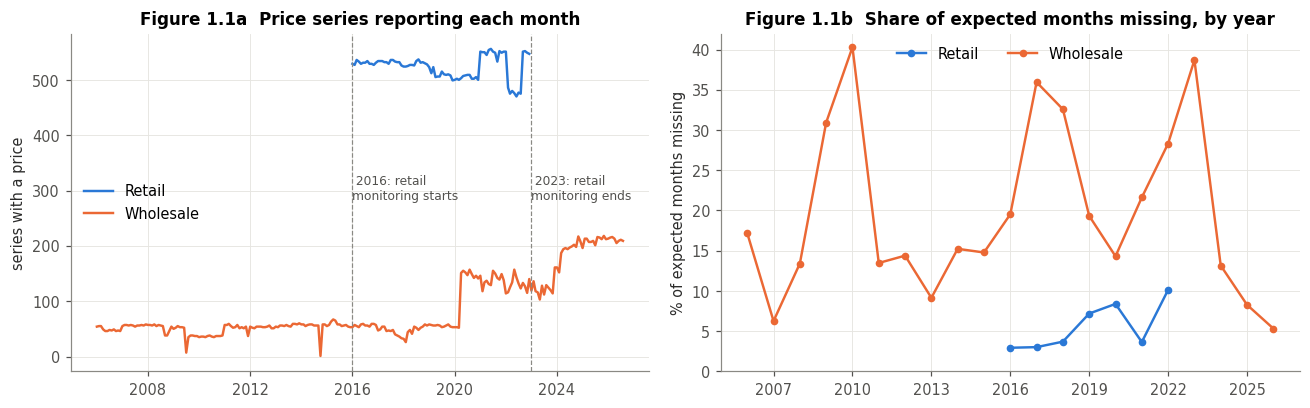

Year in which each series' LAST price appears:


last_year,2009,2014,2016,2018,2020,2021,2022,2023,2024,2026
pricetype,,,,,,,,,,
Retail,0,0,1,1,15,0,570,0,0,0
Wholesale,2,1,0,2,5,18,2,14,7,231


In [21]:
# Figure 1.1 — coverage over time: how many series report each month, by price type
cover = df.groupby(["month", "pricetype"]).size().unstack()   # NaN = price type not monitored that month
cover.index = cover.index.to_timestamp()

grid["year"] = grid["month"].dt.year
gap_year = grid.groupby(["year", "pricetype"])["missing"].mean().unstack() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for pt in ["Retail", "Wholesale"]:
    axes[0].plot(cover.index, cover[pt], color=COLOR[pt], lw=1.6, label=pt)
    axes[1].plot(gap_year.index, gap_year[pt], color=COLOR[pt], lw=1.6, marker="o", ms=4, label=pt)
for x, label in [("2016-01-01", "2016: retail\nmonitoring starts"), ("2023-01-01", "2023: retail\nmonitoring ends")]:
    axes[0].axvline(pd.Timestamp(x), color="#8a8984", lw=0.8, ls="--")
    axes[0].text(pd.Timestamp(x), 330, " " + label, va="top", fontsize=8, color="#52514e")
axes[0].set(title="Figure 1.1a  Price series reporting each month", ylabel="series with a price")
axes[1].set(title="Figure 1.1b  Share of expected months missing, by year", ylabel="% of expected months missing")
axes[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].legend(loc="center left"); axes[1].legend(loc="upper center", ncol=2)
axes[1].set_ylim(0, 42)
plt.tight_layout(); plt.show()

ended = spans.assign(last_year=spans["last"].dt.year).groupby(["last_year", "pricetype"]).size().unstack(fill_value=0)
print("Year in which each series' LAST price appears:"); ended.T

**Interpretation — the gaps are systematic, not random.**

- **Price type is the strongest driver.** Wholesale series miss **15.2%** of their months versus **2.4%** for retail; the χ² test rejects independence overwhelmingly (p ≈ 0). Wholesale prices in the older 20-market network were collected less regularly.
- **Region matters.** Missing rates range from about **1% (Simiyu)** to about **15% (Geita, Njombe, Mbeya)** (χ², p ≈ 0). The highest-gap markets (Geita and Njombe, added in 2015) report wholesale prices only intermittently, so a model would know least about exactly these places.
- **Time matters.** Wholesale gaps peak in **2009–2010** (about 27–36% of months), **2017–2018** (about 29–33%) and the **2022–2023 transition** (about 25–36%), when retail monitoring stopped and the wholesale network was reorganised (Figure 1.1b). Retail gaps never exceed about 8% in any year.
- **Season does not matter.** The calendar-month rate stays between 6.3% and 8.5%, so prices are not skipped in particular months of the agricultural year. This is reassuring: missing months are not hiding lean-season spikes.

**Discontinued series are a separate issue from gaps.** 572 of the 870 series (almost all retail) have their last price in 2022, when WFP stopped retail monitoring; only 231 series still report in September 2026. That is a change in **coverage**, not missing data, and it decides which period the model can be tested on (Section 3/4).

*Consequence for later sections:* because gaps depend on price type and region, any imputation must be done **within each series**, using **past months only** **[Condition 1]**, never with a global mean (Section 3).

### 1.3.4 Data-quality dimensions

Han, Pei & Tong (2023, Ch. 3) list six dimensions of data quality. Each is checked below against this dataset.

In [22]:
# --- ACCURACY 1: the 'MT' (metric tonne) rows -----------------------------------
# Compare each MT price with the same commodity, market type and year priced per 100 KG, scaled to per kg.
df["kg_per_unit_label"] = df["unit"].map({"KG": 1, "100 KG": 100, "MT": 1000, "L": np.nan})
df["tzs_per_kg_label"] = df["price"] / df["kg_per_unit_label"]
mt = df[df["unit"] == "MT"]
ref = (df[df["unit"] == "100 KG"].groupby(["commodity", df["date"].dt.year])["tzs_per_kg_label"].median()
         .rename("median TZS/kg from 100 KG rows"))
mt_check = (mt.assign(year=mt["date"].dt.year)
              .merge(ref, left_on=["commodity", "year"], right_index=True)
              [["date", "market", "commodity", "price", "tzs_per_kg_label", "median TZS/kg from 100 KG rows"]]
              .rename(columns={"price": "price (labelled per MT)", "tzs_per_kg_label": "implied TZS/kg if MT"}))
print(f"MT rows: {len(mt)}"); display(mt_check.head(6))
ratio = mt_check["price (labelled per MT)"] / mt_check["median TZS/kg from 100 KG rows"]
print(f"MT price ÷ same-year per-kg price from 100 KG rows: median {ratio.median():.2f}")

MT rows: 27


,date,market,commodity,price (labelled per MT),implied TZS/kg if MT,median TZS/kg from 100 KG rows
1719,2008-09-15,Dar Es Salaam,Beans,909.60,0.90960,875.00000
1757,2008-10-15,Dar Es Salaam,Beans,937.57,0.93757,875.00000
2207,2009-07-15,Dar Es Salaam,Maize,371.25,0.37125,400.00000
2208,2009-07-15,Dar Es Salaam,Rice,991.46,0.99146,1100.00000
2209,2009-07-15,Dar Es Salaam,Beans,999.13,0.99913,993.33335
2217,2009-08-15,Dar Es Salaam,Beans,1054.14,1.05414,993.33335


MT price ÷ same-year per-kg price from 100 KG rows: median 1.05


In [23]:
# --- ACCURACY 2: extreme values relative to the same commodity in the same month -------
# Price per kg relative to the national median for that commodity, price type and month.
same_unit = df[df["unit"].isin(["KG", "100 KG"])].copy()
same_unit["rel_to_national_median"] = (same_unit["tzs_per_kg_label"] /
    same_unit.groupby(["commodity", "pricetype", "date"])["tzs_per_kg_label"].transform("median"))
extreme = same_unit[(same_unit["rel_to_national_median"] > 5) | (same_unit["rel_to_national_median"] < 0.2)]
print(f"Rows more than 5× above or 5× below the national median for that commodity-month: {len(extreme)}")
extreme.sort_values("rel_to_national_median", ascending=False)[
    ["date", "market", "commodity", "unit", "price", "rel_to_national_median"]].head(8)

Rows more than 5× above or 5× below the national median for that commodity-month: 30


,date,market,commodity,unit,price,rel_to_national_median
42002,2021-01-15,Tanga Region,Beans (green),KG,3000000.0,953.076850
39216,2020-09-15,Pwani Region,Lettuce,KG,7684.9,9.372972
39860,2020-10-15,Pwani Region,Lettuce,KG,7008.4,8.352282
38562,2020-08-15,Pwani Region,Lettuce,KG,6549.8,7.866683
44563,2021-05-15,Pwani Region,Lettuce,KG,5609.4,7.370122
45945,2021-07-15,Pwani Region,Lettuce,KG,5473.2,7.247832
46650,2021-08-15,Pwani Region,Lettuce,KG,5624.2,7.143656
39219,2020-09-15,Pwani Region,Tomatoes (bitter),KG,7493.0,7.088931


In [24]:
# --- CONSISTENCY 1: does usdprice agree with price? (implied TZS per USD) ---------------
df["implied_tzs_per_usd"] = df["price"] / df["usdprice"]
yearly_rate = df.groupby(df["date"].dt.year)["implied_tzs_per_usd"].transform("median")
off = df[(df["implied_tzs_per_usd"] / yearly_rate - 1).abs() > 0.5]
print(f"Rows whose implied exchange rate is >50% away from that year's median: {len(off)}")
display(off[["date", "market", "commodity", "price", "usdprice", "implied_tzs_per_usd"]].head(5))

# --- CONSISTENCY 2: units used by each commodity ---------------------------------------
units = pd.crosstab(df["commodity"], [df["pricetype"], df["unit"]])
print("Commodities recorded in more than one unit / price type:")
display(units[(units > 0).sum(axis=1) > 1])

# --- CONSISTENCY 3: markets table vs price table ----------------------------------------
m = df.drop_duplicates("market_id")[["market_id", "market", "latitude", "longitude"]].merge(
        markets, on="market_id", how="left", suffixes=("", "_mk"))
print(f"Price-table markets missing from markets table: {m['market_mk'].isna().sum()}; "
      f"name mismatches: {(m['market'] != m['market_mk']).sum()}; "
      f"coordinate mismatches: {((m['latitude'] != m['latitude_mk']) | (m['longitude'] != m['longitude_mk'])).sum()}")

Rows whose implied exchange rate is >50% away from that year's median: 62


,date,market,commodity,price,usdprice,implied_tzs_per_usd
608,2007-01-15,Lindi,Maize,23700.00,2.0,11850.00000
681,2007-02-15,Mwanza,Maize,23700.00,2.0,11850.00000
1284,2008-01-15,Lindi,Beans,115300.00,1.0,115300.00000
1748,2008-09-15,Singida,Beans,103500.00,9.0,11500.00000
4205,2013-02-15,Shinyanga,Beans,128954.55,8.0,16119.31875


Commodities recorded in more than one unit / price type:


pricetype        Retail    Wholesale    
unit                 KG  L    100 KG  MT
commodity                               
Beans                 0  0      4394  19
Maize                 0  0      4709   7
Potatoes (Irish)   2066  0      1787   0
Rice               2033  0      4791   1

Price-table markets missing from markets table: 0; name mismatches: 0; coordinate mismatches: 0


In [25]:
# --- COMPLETENESS (coverage): which markets in the markets table never report a price? ----
no_prices = markets[~markets["market_id"].isin(df["market_id"])]
print(f"Markets listed: {len(markets)}; with at least one price: {df['market_id'].nunique()}; without: {len(no_prices)}")
print("Markets without any price, by region:", no_prices["admin1"].value_counts().to_dict())
zanzibar = ["Mjini Magharibi", "Kaskazini Unguja", "Kusini Unguja", "Kaskazini Pemba", "Kusini Pemba"]
print(f"Price rows from Zanzibar regions: {df['admin1'].isin(zanzibar).sum()}")

# --- TIMELINESS: three monitoring regimes ----------------------------------------------------
regime = pd.cut(df["date"].dt.year, [2005, 2015, 2022, 2026], labels=["2006–2015", "2016–2022", "2023–2026"])
df.groupby(regime, observed=True).agg(rows=("price", "size"), markets=("market_id", "nunique"),
                                      commodities=("commodity", "nunique"),
                                      price_types=("pricetype", lambda s: ", ".join(sorted(s.unique()))))

Markets listed: 123; with at least one price: 63; without: 60
Markets without any price, by region: {'Kigoma': 15, 'Mwanza': 10, 'Dar-es-salaam': 9, 'Mjini Magharibi': 9, 'Mtwara': 9, 'Lindi': 7, 'Kaskazini Unguja': 1}
Price rows from Zanzibar regions: 0


,rows,markets,commodities,price_types
date,,,,
2006–2015,6110,23,3,Wholesale
2016–2022,51126,55,31,"Retail, Wholesale"
2023–2026,7871,33,8,Wholesale


**Quality summary.** Each finding is tied to an action taken later, so nothing is fixed silently.

| Dimension | What was checked | Finding | Action (section) |
|---|---|---|---|
| **Accuracy** | MT rows vs same-year per-kg prices | All **30 “MT” rows** have prices of a few hundred TZS — about **1×** the per-kg price, not 1,000×. They are **mislabelled per-kg prices**; dividing by 1,000 would create absurd values. | Treat as TZS/kg when converting units **[Condition 3]** (§3) |
| **Accuracy** | Price vs national median for that commodity-month | **34 rows** are more than 5× away from the national median. Most are plausible but suspicious (Pwani Region lettuce at 7–10× the median over 2020–21); one is clearly impossible: **green beans in Tanga Region (Jan 2021) at 3,000,000 TZS/kg**, about 930× the median: a data-entry error. | Flag outliers *within each series* using training-period limits (§3) |
| **Completeness** | Explicit + implicit missingness | 0 empty cells; **5,141 of 73,140 expected months (7.0%) have no row**, concentrated in wholesale series and some regions (systematic, 1.3.3). | Within-series, past-only handling **[Condition 1]** (§3) |
| **Completeness** (coverage) | Markets table vs price table | 60 of 123 listed markets never report a price, including **all 10 Zanzibar markets** — the price data cover **mainland Tanzania only**. | State as a limit; do not apply the model to Zanzibar (§5 ethics) |
| **Consistency** | Units; `usdprice` vs `price`; two tables | Four units (KG, 100 KG, MT, L); **65 rows** where `usdprice` implies an impossible exchange rate (a dropped digit: a factor of 10–100); markets table and price table agree exactly on names and coordinates. | Use `price` (TZS) only and drop `usdprice` (§3) |
| **Timeliness** | Coverage by period | Three regimes: 2006–15 (23 markets, 3 commodities, wholesale only), 2016–22 (55 markets, 31 commodities, retail + wholesale), 2023–26 (33 markets, **8 commodities, wholesale only**). Latest month Sep 2026. | Choose training/test periods with these regimes in mind (§3–4) |
| **Believability** | Source | Compiled and published by WFP, an official UN agency, as part of its routine market monitoring. | — |
| **Interpretability** | Meaning of fields | Mostly clear, but `date` is a month stamped on the 15th, and `priceflag`/`currency` are constant. | Use month periods; drop constant columns (§3) |

### 1.4 Target definition (stated now, computed later)

- **Target:** `price_spike` for series *s* in month *t+1* = **1** if price(*t+1*) > 1.10 × price(*t*) for the **same series**, with prices in TZS/kg, and **0** otherwise.
- The label is only defined when months *t* and *t+1* are both observed; months next to a gap get no label rather than an invented one.
- **Features** for predicting month *t+1* may only use months ≤ *t* **[Condition 1]**.
- The 10% threshold is justified in Section 2 using the **training period only**, with a sensitivity check at other thresholds **[Condition 2]**. Choosing it from the full data would let the test period influence a modelling choice, which the rubric counts as leakage.

---
# References

**Data**
- World Food Programme (2026). *United Republic of Tanzania — Food Prices* and *Markets*. Humanitarian Data Exchange. https://data.humdata.org/dataset/wfp-food-prices-for-united-republic-of-tanzania. CC BY-IGO. Downloaded 9 November 2026.

**Course and textbook**
- Nyalala, I. (2026). *Z3003 Data Mining: Scaling to Large Data*, Lectures 1–3 and Tutorial 1. IIT Madras Zanzibar.
